In [ ]:
import numpy as np
from scipy import optimize
import matplotlib.pyplot as plt


# Introduction to numerical algorithms
## Practice class 10 - Numerical optimization: root and extremum finding, Fixed point, Gradient Descent

Resources:
- [Optimization in Python: Techniques, Packages, and Best Practices](https://www.datacamp.com/tutorial/optimization-in-python)
- **Primer on Programming in Python and Mathematical/Computational Techniques for Scientists and Engineers**, Department of Earth Science and Engineering, Imperial College London Lecture series
- [SciPy Lectures](https://lectures.scientific-python.org/index.html)
- Bernard Knaepen & Yelyzaveta Velizhanina, **Numerical methods for partial differential equations** [link](https://aquaulb.github.io/book_solving_pde_mooc/solving_pde_mooc/notebooks/01_Introduction/01_00_Preface.html)
- Indranil Ghosh, **Mathematical Optimization**, [link](https://indrag49.github.io/Numerical-Optimization/conjugate-gradient-methods-1.html)

## The simplest way - Fixed point method

We are looking for a root of $f(x)$. If 

$$
f(x)=0,
$$

then

$$
f(x)+x=g(x)=x\;.
$$

Giving the fixed point formula, so we have to perform the iteration:

$$
x_{n+1}=g(x_n)
$$

Or in its generalized form $g(x)=x-\alpha f(x)$. 

### Task 1 

1. Implement the fixed point iteration method, write the function `fixed_point(f,x0,alpha,tol,maxiter)`, where `f` is the original function, `x0` is the starting point of the iteration, `alpha` is the relaxation parameter, `tol` is the tolerance for the difference of the latest two iteration and `itermax` is the maximal number of iteration.
2. Find the positive root of $f(x)=x^2-2$. What are the optimal `x0` and `alpha` parameters?
3. Creat a Cobweb plot of the first 15 step of the iteration. For that plot $y=x$ and $y=g(x)$ and the following path:
$$
x_0 \rightarrow g(x_0) \rightarrow x_1 \rightarrow g(x1) \rightarrow \ldots \rightarrow x_{15} \rightarrow g(x_{15})
$$
4. What is the range in $\alpha$ for which the method is convergent? Experiment with different `alpha` and `x0` parameters!

## Playing with the bisection method

The simplest root finding algorithm is the [bisection method](https://en.wikipedia.org/wiki/Bisection_method).  This operates by narrowing an interval which is known to contain a root.  Assuming $f$ is continuous, we can use the [intermediate value theorem](https://en.wikipedia.org/wiki/Intermediate_value_theorem). We know that if $f(a) < 0$, and $f(b) > 0$, there must be some $c\in (a,b)$ so that $f(c) = 0$.  At each iteration, we narrow the interval by looking at the midpoint $c = (a + b)/2$ and then looking at the interval $(a,c)$ or the interval $(c,b)$ depending on which one contains a root based on the intermediate value theorem.

### Task 2

Implement the bisection method.
- you have multiple options: you can implement it recursively or as a sequential version
- keep tracking of the sign change: this will give you the interval, where you should look for your root
- return the number of iterations, function evaluations and the root guesses, $x^*$-s
- you should have a `tol` tolerance parameter, which will give how close you want to go to the minima
- try it on some dummy function such as $f(x)=x^2-4$
- Plot the function and the root! Add errorbar on the x-axis at the root marking the uncertainty coming from the tolerance

## Papa Newton comes into play

[Newton's method](https://en.wikipedia.org/wiki/Newton%27s_method) is another root finding method.  A **root** of a continuous function $f$ is a value $x$ so that $f(x) = 0$.

Given a function $f$, we would like to find some root $x$. Newton's method computes a sequence of iterations
$$ x_{k+1} = x_{k} - \frac{f(x_{k})}{f'(x_{k})}$$

Notice that this assumes a couple of things:
1. The function is known 
2. The function is smooth and at least C1 (continously differentiable once) on the interval where we want to find the root.
3. The derivative is not 0 on the interval

Showcasing the idea:

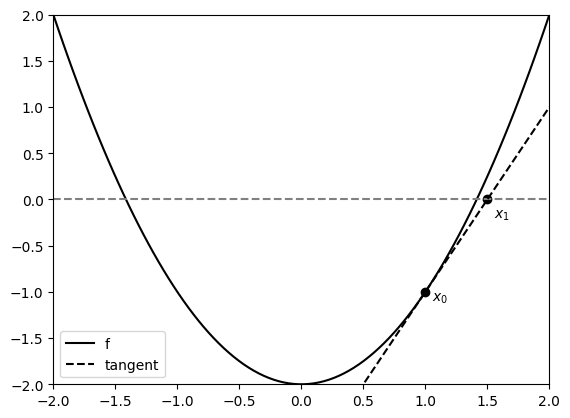

In [3]:
f = lambda x : x**2 - 2
fp = lambda x : 2*x

xmin, xmax = -2, 2
xs = np.linspace(xmin, xmax, 100)
x0 = 1
plt.plot(xs, f(xs), 'k-', label='f') # plot the function
plt.hlines(0, xmin, xmax, colors='gray', linestyles='dashed') # dashed line for y = 0
plt.scatter(x0, f(x0), c='k')
plt.text(x0 + 0.05, f(x0) - 0.1, r'$x_0$') # x0 label
x1 = x0 - f(x0)/fp(x0)
plt.plot(xs, fp(x0)*(xs - x1), 'k--', label='tangent')
plt.scatter(x1, 0, c='k')
plt.text(x1 + 0.05, -0.2, r'$x_1$') # x1 label
plt.xlim(xmin, xmax)
plt.ylim(xmin, xmax)
plt.legend()
plt.show()

### Task 3

1. Write a function that finds the root of a function with the Newton method.
2. Check if your method works on dummy simple function. You can use the ones from bisection method for comparison reasons
3. Take the following function: $f(x)=x^3+2x^2+5x+1$. Find the roots with both methods! Compare the convergence of the two methods on a plot!
4. Calculate the [rate of convergence](https://en.wikipedia.org/wiki/Rate_of_convergence):

**Rate of Convergence**
Mostly, we're interested in the ratio $\epsilon_{k+1} / \epsilon_k$.  We say the convergence of $\epsilon$ is of order $q$ if

$$
\lim_{k\to \infty} \frac{\epsilon_{k+1}}{\epsilon_k^q} < C
$$

for some constant $C> 0$.

* $q = 1$ and $C \in (0,1)$ is called *linear* convergence
* $q = 2$ is called *quadratic* convergence

Larger values of $q$ indicate faster convergence.

Additionally, we have the following terms:
* $q = 1$ and $C = 1$ is called *sublinear* (slower than linear) convergence
* $q > 1$ is *superlinear* (faster than linear) convergence

Clearly, if $q= 1, C > 1$, or if $q < 1$, the sequence actually diverges.

Show Newton method has quadratic and bisection method has linear convergence!

### Task 4 - Numerics goes brr and Newton gets on steroids

If you already did not notice, then we have a problem, Houston. When using Newton's method, we need to know explicitly the derivative. What if we don't know it? Well then we can cook up some clever ways to calculate/approximate it numerically! Take a look at the definition of the derivative:
$$f'(x) = \lim_{h\to 0^+} \frac{f(x) - f(x + h)}{h}$$
Using the symmetric definition
$$f'(x) = \lim_{h\to 0^+} \frac{f(x+h) - f(x - h)}{2h}$$

Defining a non-limit version
$$\Delta_h f(x) = \frac{f(x + h) - f(x - h)}{2h}$$
for fixed $x$, if $h$ is sufficiently small, then $\Delta_h f \approx f'$ near $x$.  $\Delta_h f$ is known as *finite difference*.

1. Using this approach code a new method that uses this idea to calculate the derivative and then find the root via Newton with the numerical derivative! This is called the **Secant method**.
2. Compare the needed iteration for $h$ values taken from a logspace of (-1,-15).
3. Compare the convergences of the analytical and numerical Newton. for $h$-s ranging from $1^{-1}$ to $1^{-5}$.

## Gradient Descent Methods

Gradient descent is an iterative optimization technique for finding (local) minima of differentiable functions. It is widely used in machine learning (e.g., to minimize cost/loss functions).

### Cost Function: The Goal of Optimization

We define a cost (or loss) function $J(\theta)$ which measures how “bad” our current parameters ($\theta$) are. For example, in linear regression we might use Mean Squared Error (MSE):
$$
\text{MSE} = \frac1n \sum_{i=1}^n (y_i - \hat y_i)^2
$$
or equivalently $ \frac1{2n} \sum (y_i - \hat y_i)^2 $ for convenience.
Our aim: find $\theta$ which minimises $J(\theta)$.

### Gradient of a Function: Calculus Refresher

If $f: \mathbb R^r \to \mathbb R$, the gradient $\nabla f(\mathbf x)\in\mathbb R^r$ is the vector of partial derivatives:
$$
\nabla f(x_1,\dots,x_r) = \Big(\frac{\partial f}{\partial x_1}, \dots, \frac{\partial f}{\partial x_r}\Big).
$$
The gradient points in the direction of steepest *increase*. Hence, moving in the direction of the **negative** gradient gives steepest *decrease*.

### Intuition Behind Gradient Descent

Picture a ball rolling down a hill: it goes in direction of steepest descent until reaching a valley. That’s the metaphor for gradient descent: from a starting vector $\mathbf x^{(0)}$, we iteratively update
$$
\mathbf x_{n+1} = \mathbf x_{n} - \eta \nabla f(\mathbf x_n)
$$
where $\eta > 0$ is the **learning rate**.
Key issues:

* If $\eta$ too small → very slow convergence.
* If $\eta$ too big → may overshoot or diverge.
* If function non-convex → might get stuck in local minima or saddle points.


Let’s begin with a simple implementation in Python using NumPy.


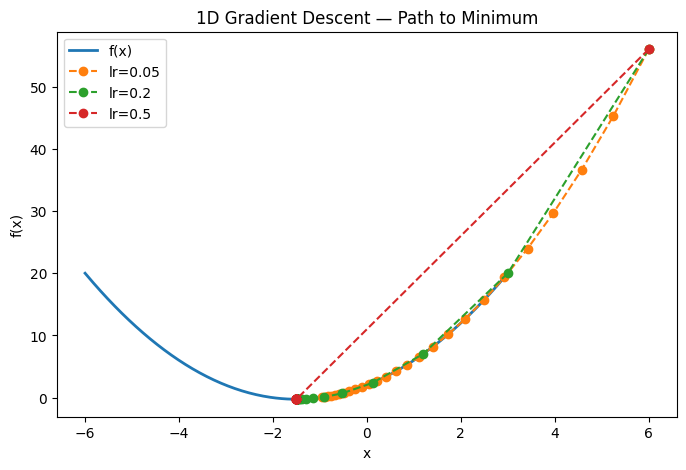

In [ ]:
# Function and derivative
f  = lambda x: x**2 + 3*x + 2
df = lambda x: 2*x + 3

def gradient_descent_1d(grad, start, lr, n_iter=20):
    x = start
    history = [x]
    for _ in range(n_iter):
        x -= lr * grad(x)
        history.append(x)
    return np.array(history)

# Run for a few learning rates
lrs = [0.05, 0.2, 0.5]
x_vals = np.linspace(-6, 3, 300)

plt.figure(figsize=(8,5))
plt.plot(x_vals, f(x_vals), label='f(x)', lw=2)

for lr in lrs:
    path = gradient_descent_1d(df, start=6.0, lr=lr, n_iter=25)
    plt.plot(path, f(path), 'o--', label=f'lr={lr}')
    
plt.title("1D Gradient Descent — Path to Minimum")
plt.xlabel("x"); plt.ylabel("f(x)")
plt.legend(); plt.show()


### Task 5

1. Use gradien descent on $f(v) = v^2$ with various learning‐rates: $\eta = 0.005,0.2,0.8$. Start at $v=10$. Observe and record how quickly (or if) it converges.
2. Plot the path of `v` through iterations for each learning‐rate (for example store all intermediate `vector`s). Comment on what you observe.

*Discussion of results:*

* For η=0.005: very slow; might not get near zero in 50–200 iterations.
* For η=0.2: good convergence.
* For η=0.8: potentially oscillates/overshoots before converging (or might diverge depending on iterations). This illustrates sensitivity of the learning rate.


## Gradient method in $n$-dimensions (Demo)

Let $F(\mathbf{x})$ be a differentiable $n$ dimensional function and we are loking for the minima of this function. If $\gamma>0$, then after the operation 
$$\mathbf{x}_{n+1} = \mathbf{x}_n-\gamma\nabla F(\mathbf{x}_n),$$
Then using the Taylor expansion to second order and solving for the minima we get the following step size:
$$\gamma_{n} = \frac{|(\mathbf x_{n} - \mathbf x_{n-1})^T[\nabla F(\mathbf x_{n}) - \nabla F(\mathbf x_{n-1})]|}{||\nabla F(\mathbf x_{n}) - \nabla F(\mathbf x_{n-1})||^2}$$

In [ ]:
def gradient_descent_nD(grad_fn, start, lr=1e-4, n_iter=10000, tol=1e-6, clip=100.0):
    """
    Generic n-dimensional gradient descent.
    
    Parameters
    ----------
    grad_fn : callable
        Function that takes a parameter vector and returns its gradient (same shape).
    start : array-like
        Initial parameter vector.
    lr : float
        Learning rate.
    n_iter : int
        Number of iterations.
    tol : float
        Stopping threshold based on gradient magnitude.
    clip : float
        Maximum allowed gradient norm (for clipping).
    Returns
    -------
    np.ndarray
        Array of shape (n_steps, n_dims) containing the path of points visited.
    """
    point = np.array(start, dtype=float)
    path = [point.copy()]
    for _ in range(n_iter):
        grad = np.array(grad_fn(point))
        # Gradient clipping
        grad_norm = np.linalg.norm(grad)
        if grad_norm > clip:
            grad = grad * (clip / grad_norm)
        if grad_norm < tol:
            break
        point -= lr * grad
        path.append(point.copy())
    return np.array(path)


In [ ]:
def f_elliptical(p):
    x, y = p
    return x**2 + 20*y**2

def grad_elliptical(p):
    x, y = p
    return np.array([2*x, 20*y])
    

def f_saddle(p):
    x, y = p
    return x**2 - y**2

def grad_saddle(p):
    x, y = p
    return np.array([2*x, -2*y])


def f_rosenbrock(p):
    x, y = p
    return (1 - x)**2 + 100*(y - x**2)**2

def grad_rosenbrock(p):
    x, y = p
    dx = -2*(1 - x) - 400*x*(y - x**2)
    dy = 200*(y - x**2)
    return np.array([dx, dy])

def f_sin(p):
    x, y = p
    return np.sin(x) * np.cos(y) + 0.1 * (x**2 + y**2)

def grad_sin(p):
    x, y = p
    dx = np.cos(x) * np.cos(y) + 0.2*x
    dy = -np.sin(x) * np.sin(y) + 0.2*y
    return np.array([dx, dy])


def f_rastrigin(p, A=10):
    x, y = p
    return A*2 + (x**2 - A*np.cos(2*np.pi*x)) + (y**2 - A*np.cos(2*np.pi*y))

def grad_rastrigin(p, A=10):
    x, y = p
    dx = 2*x + 2*np.pi*A*np.sin(2*np.pi*x)
    dy = 2*y + 2*np.pi*A*np.sin(2*np.pi*y)
    return np.array([dx, dy])

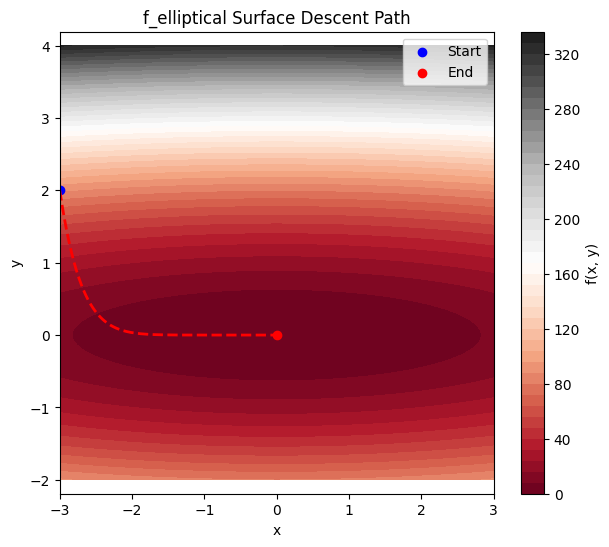

In [ ]:
# Choose your surface
f = f_elliptical
grad = grad_elliptical

# Run GD
path = gradient_descent_nD(grad, start=[-3, 2], lr=0.001, n_iter=10000)

# Plot contours
x = np.linspace(-3, 3, 400)
y = np.linspace(-2, 4, 400)
X, Y = np.meshgrid(x, y)
Z = np.array([[f([xi, yi]) for xi, yi in zip(row_x, row_y)] for row_x, row_y in zip(X, Y)])

plt.figure(figsize=(7,6))

contour = plt.contourf(X, Y, Z, levels=50, cmap='RdGy')

plt.plot(path[:,0], path[:,1], 'r--', lw=2)
plt.scatter(path[0,0], path[0,1], c='blue', label='Start')
plt.scatter(path[-1,0], path[-1,1], c='red', label='End')

cbar = plt.colorbar(contour)
cbar.set_label('f(x, y)')

plt.title(f"{f.__name__} Surface Descent Path")
plt.xlabel('x'); plt.ylabel('y')
plt.legend(); plt.axis('equal')
plt.show()
